# 05 — Cross-market factors (`EXP-H20`)

## 1. Objective
Test whether lagged state from markets outside crypto improves BTCUSDT return-density forecasts beyond own-price history.

## 2. Hypothesis
Lagged SPX, US 10-year, gold, WTI, and USD-factor state improves 5-, 15-, and 60-minute predictive density. A combined model is preferred only when it also beats the crypto-factor ablation and the external-only model.

## 3. Null
External-market state adds no density-forecast value beyond own-price history at every declared horizon.

## 4. Information set
One-minute Binance closes for BTCUSDT, ETHUSDT, BNBUSDT, XRPUSDT, ADAUSDT, and SOLUSDT. One-minute OANDA closes for SPX500_USD, USB10Y_USD, XAU_USD, WTICO_USD, EUR_USD, GBP_USD, AUD_USD, USD_JPY, USD_CAD, and USD_CHF. Features are delayed by one minute. Equity implied volatility is not in the versioned store and is not proxied. No session is forward-filled.

## 5. Dataset
`cross-market-1m`. The aggregate manifest binds each member venue, object version, and the complete-case alignment interval.

## 6. Data quality
Each member receives the standard minute-bar audit. Cross-market timestamps are inner-aligned without forward filling. Excluded timestamps and post-freeze collector rows are counted.

## 7. Labels
Forward BTCUSDT log returns at 5, 15, and 60 minutes. A label belongs to a split only when its outcome is known inside that split.

## 8. Baseline
A Gaussian or Student-t conditional-location density using lagged BTCUSDT one-minute return and 60-minute realised volatility. The residual family is selected by H1.

## 9. Model family
The nested ladder is own-price, own-price plus the H3 single-factor crypto residual, own-price plus lagged external state, and both states together. External state is the lagged SPX, US 10-year, gold, and WTI return plus a frozen-sign equal-weight USD factor. The crypto residual is an ablation, not a claim that H3 was retained.

## 10. Splits
24-month train, 6-month validation, 6-month step, and final 12-month untouched test.

## 11. Configuration
The source of truth is `research.protocol.H20_CONFIG`. The development path cannot retain H20. Sealed confirmation requires a resolved H1 record, committed code, the pre-registered configuration, and immutable versions for every panel object.

In [1]:
import os
import sys
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

root = Path.cwd().resolve()
while root != root.parent and not (root / "research" / "__init__.py").exists():
    root = root.parent
if not (root / "research" / "__init__.py").exists():
    raise RuntimeError("open this notebook from the trading repository")
os.chdir(root)
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
os.environ.setdefault("AWS_PROFILE", "trading")
os.environ.setdefault("AWS_DEFAULT_REGION", "ap-southeast-2")
os.environ.setdefault("DATA_STORE", "s3")
os.environ.setdefault("S3_BUCKET", "trading-data-centheos")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.6g}".format)

from research.registry import config_digest, load_record
from research.report import (
    calibration_summary,
    confirmation_blockers,
    model_colors,
    plain_english_result,
    plot_advantage_by_origin,
    plot_density_panels,
    plot_pit_qq,
    plot_score_levels,
    plot_shortfall,
    plot_var_hit_rates,
    quality_table,
    record_development_decision,
    score_reading,
)

## 5–6. Dataset and data quality

The frozen manifest is reloaded and verified. Every audit exclusion is counted in the table.

In [2]:
from research.evaluate import align_to_frozen_panel, freeze_panel_dataset
from research.load import load_research_series
from research.manifest import load_panel_manifest, save_panel_manifest
from research.protocol import H20_CONFIG

symbols = tuple(H20_CONFIG["symbols"])
series = tuple((H20_CONFIG["venues"][symbol], symbol) for symbol in symbols)
bars_by_symbol, objects_by_symbol = load_research_series(
    series,
    timeframe=H20_CONFIG["timeframe"],
    bucket=H20_CONFIG["bucket"],
    profile=H20_CONFIG["profile"],
    region=H20_CONFIG["region"],
)
panel_manifest_path = root / "research" / "registry" / "datasets" / "cross-market-1m.json"
if panel_manifest_path.exists():
    panel_manifest = load_panel_manifest(panel_manifest_path)
    panel_closes, quality_reports, collector_rows_after_freeze = align_to_frozen_panel(
        bars_by_symbol, panel_manifest, objects_by_symbol
    )
else:
    panel_closes, panel_manifest, quality_reports = freeze_panel_dataset(
        bars_by_symbol,
        objects_by_symbol,
        dataset_id=H20_CONFIG["panel_dataset_id"],
        symbols=symbols,
        venue="cross-venue",
        venues=dict(H20_CONFIG["venues"]),
        timeframe=H20_CONFIG["timeframe"],
        bucket=H20_CONFIG["bucket"],
        profile=H20_CONFIG["profile"],
    )
    save_panel_manifest(panel_manifest_path, panel_manifest)
    collector_rows_after_freeze = {symbol: 0 for symbol in symbols}
print(f"panel {panel_manifest.dataset_id} ({panel_manifest.venue}) digest {panel_manifest.digest}")
print(
    f"aligned rows {len(panel_closes)}; timestamps dropped by complete-case alignment "
    f"{panel_manifest.alignment_exclusions}. Traditional markets close, so only minutes when every market traded are kept."
)
print("not tested because no versioned series exists:", H20_CONFIG["unavailable_classes"])
quality = quality_table(quality_reports)
quality["venue"] = pd.Series(H20_CONFIG["venues"])
quality["collector_rows_after_freeze"] = pd.Series(collector_rows_after_freeze)
display(quality)

Excluded 10547 collector rows after frozen end 2026-10-19T01:45:00+00:00; ohlcv/binance/BTCUSDT/1m/2026.parquet etag a43efdd76cf3a0b96ef227ee17575f97 -> 9970509376d39c14e5d0558776dd454b, size 5542901 -> 5816494
Excluded 10547 collector rows after frozen end 2026-10-19T01:45:00+00:00; ohlcv/binance/ETHUSDT/1m/2026.parquet etag c3fc885f84f0c15dcc7745152d06549c -> 930a820c361e3ff838fd512941c22926, size 5110121 -> 5359777
Excluded 10547 collector rows after frozen end 2026-10-19T01:45:00+00:00; ohlcv/binance/BNBUSDT/1m/2026.parquet etag 757f29ac2f8b0a3ae7bd8fe750c7c7bb -> 0219bb27c729068ad4da4b19c659e21c, size 3733145 -> 3926342
Excluded 10547 collector rows after frozen end 2026-10-19T01:45:00+00:00; ohlcv/binance/XRPUSDT/1m/2026.parquet etag 8c00212903663fa5732d80cf20375d91 -> a5b29fb197e591af9d7da14c7dca03ec, size 8619577 -> 8814339
Excluded 10547 collector rows after frozen end 2026-10-19T01:45:00+00:00; ohlcv/binance/ADAUSDT/1m/2026.parquet etag d51297715926498ab5f204e59ed8beb5 -> 662

panel cross-market-1m (cross-venue) digest ee0a479c6ead2e2559075b5c0f8b2352683289d753122512973e728729dbe9e4
aligned rows 1078785; timestamps dropped by complete-case alignment 2496841. Traditional markets close, so only minutes when every market traded are kept.
not tested because no versioned series exists: ['equity_implied_volatility']


,rows_in,rows_kept,duplicate_timestamps,off_grid_timestamps,nonpositive_prices,inconsistent_ohlc,missing_minutes,largest_gap_minutes,venue,collector_rows_after_freeze
series,,,,,,,,,,
BTCUSDT,3575626,3575626,0,0,0,0,0,1,binance,10547
ETHUSDT,3575626,3575626,0,0,0,0,0,1,binance,10547
BNBUSDT,3517545,3517545,0,0,0,0,0,1,binance,10547
XRPUSDT,3567925,3567925,0,0,0,0,0,1,binance,10547
ADAUSDT,3531945,3531945,0,0,0,0,0,1,binance,10547
SOLUSDT,3205126,3205126,0,0,0,0,0,1,binance,10547
SPX500_USD,2323977,2323977,0,0,0,0,1250269,4606,oanda,7361
USB10Y_USD,1266564,1266564,0,0,0,0,2307682,4606,oanda,4463
XAU_USD,2397841,2397841,0,0,0,0,1176405,4576,oanda,7347


## 12–17. Evaluation

The evaluation compares own-price history with three nested additions: the lagged H3 crypto-factor residual, lagged external-market state, and both together. The null is rejected only when external-market state has a positive mean and median log-score advantage at every horizon. The combined model is preferred only if it also beats both the crypto-only and external-only models.

- **12. Statistical evaluation.** Mean log score per walk-forward origin, PIT, and VaR coverage on the fixed model-by-horizon family.
- **13. Economic evaluation.** None. This hypothesis is predictive only.
- **14. Calibration.** PIT QQ and Bonferroni-adjusted VaR coverage, below.
- **15. Ablation.** The nested sequence is listed in §9.
- **16. Robustness.** Every rolling origin and every registered horizon must agree. A change of configuration is a new experiment.
- **17. Failure analysis.** Failed windows, exclusions, and gaps are counted and printed. A failed window is never scored as zero.

In [3]:
from research.evaluate import evaluate_h20, h20_development_decision, h20_development_fits, h20_log_score_comparison, h20_var_coverage_family

CONFIG = H20_CONFIG
EXPERIMENT_ID = "EXP-H20"
RECORD_PATH = root / "research" / "registry" / "EXP-H20.json"
DATASET_ID, DATASET_DIGEST = panel_manifest.dataset_id, panel_manifest.digest
h1_record = load_record(root / "research" / "registry" / "EXP-H01.json")
print("configuration digest:", config_digest(CONFIG))
print(f"H1 status={h1_record.status} result={h1_record.result} decision={h1_record.decision or '(blank)'}")
evaluation = evaluate_h20(panel_closes, h1_record, CONFIG)
if evaluation.sealed_access:
    raise RuntimeError("development notebook read the sealed test")
comparison = h20_log_score_comparison(evaluation.scores)
coverage = h20_var_coverage_family(evaluation.scores)
verdict = h20_development_decision(comparison).iloc[0]
BENCHMARK = "own_price"
CANDIDATES = ("crypto_factor", "external_factor", "combined")
MODELS = (BENCHMARK, *CANDIDATES)
LABELS = {
    "own_price": "own-price",
    "crypto_factor": "crypto factor",
    "external_factor": "external markets",
    "combined": "external + crypto",
}
ALPHA = float(CONFIG["var_alpha"])
QUESTION = (
    "Does lagged state from equities, US rates, gold, oil, and the US dollar improve the BTCUSDT return density "
    "beyond BTC's own price history?"
)
GATE_H1_RECORD = h1_record
GATE_OBJECTS = [item for member in panel_manifest.members for item in member.objects]
print(
    f"density family {evaluation.benchmark} (resolved={evaluation.benchmark_resolved}); "
    f"feature/label exclusions {evaluation.alignment_exclusions}; failed windows {len(evaluation.failures)}; "
    f"sealed access {evaluation.sealed_access}"
)

configuration digest: b9e25cf08d6e002f8070876d78b2a49e67752715453cea29809349663d9c3266
H1 status=Exploratory result=student_t decision=(blank)


Panel return construction excluded 270062 non-consecutive/initial rows
Excluded 367140 gap and 0 non-positive 5-minute returns
Excluded 376123 gap and 0 non-positive 15-minute returns
Excluded 403603 gap and 0 non-positive 60-minute returns
Dropped 50452 own_price training labels with unavailable lagged features
Dropped 50452 crypto_factor training labels with unavailable lagged features
Dropped 50452 external_factor training labels with unavailable lagged features
Dropped 50452 combined training labels with unavailable lagged features
Dropped 13851 own_price scoring labels with unavailable lagged features
Dropped 13851 crypto_factor scoring labels with unavailable lagged features
Dropped 13851 external_factor scoring labels with unavailable lagged features
Dropped 13851 combined scoring labels with unavailable lagged features
Dropped 50119 own_price training labels with unavailable lagged features
Dropped 50119 crypto_factor training labels with unavailable lagged features
Dropped 501

density family student_t (resolved=True); feature/label exclusions 1207206; failed windows 0; sealed access False


## How to read the scores

The first table compares each candidate with the benchmark at every horizon.

- `mean_advantage` and `median_advantage` are the candidate's mean log score minus the benchmark's, in nats per validation return. Positive means the candidate put more probability on what actually happened.
- `density_change_pct` restates the mean advantage as a percentage change in geometric-mean forecast density. It is a forecast-quality measure, not a trading return.
- `origins_ahead` counts the walk-forward origins where the candidate won.

The second table is the same advantage at each origin. The third is tail calibration: `median_var_hit_rate` should be close to `var_target`, and `coverage_rejected` is true when the Bonferroni-adjusted VaR test rejects that model. These cells use the scores already computed. They do not refit a model or read the sealed year.

In [4]:
reading, per_origin = score_reading(evaluation.scores, benchmark=BENCHMARK, candidates=CANDIDATES)
calibration = calibration_summary(evaluation.scores, coverage, alpha=ALPHA)
print(f"Log-score advantage over {LABELS[BENCHMARK]} (positive means the candidate forecast better)")
display(reading)
print("Advantage at each walk-forward origin (nats)")
display(per_origin)
print(f"Tail calibration against the {ALPHA:.0%} VaR")
display(calibration)
if evaluation.failures:
    print("Failed windows (excluded, not counted as zero):")
    display(pd.DataFrame(evaluation.failures))

Log-score advantage over own-price (positive means the candidate forecast better)


,horizon_minutes,candidate,benchmark,mean_advantage,median_advantage,min_advantage,max_advantage,origins_ahead,origins,density_change_pct,benchmark_score,candidate_score
0,5,crypto_factor,own_price,-5.94426e-05,-5.2767e-05,-0.000190848,4.24515e-05,3,6,-0.00594409,4.86825,4.86819
1,15,crypto_factor,own_price,-4.34028e-05,-4.64411e-05,-9.47105e-05,2.84906e-05,1,6,-0.00434019,4.32558,4.32554
2,60,crypto_factor,own_price,-1.4832e-05,7.56112e-08,-8.12843e-05,3.61814e-05,3,6,-0.00148318,3.621,3.62098
3,5,external_factor,own_price,-0.000100995,-6.95623e-05,-0.000390298,9.46342e-05,2,6,-0.010099,4.86825,4.86815
4,15,external_factor,own_price,-0.000147382,-3.66569e-05,-0.000465204,2.68147e-05,1,6,-0.0147371,4.32558,4.32544
5,60,external_factor,own_price,-0.000148769,-0.000100583,-0.000434221,2.56733e-05,1,6,-0.0148758,3.621,3.62085
6,5,combined,own_price,-0.000157139,-0.000111943,-0.00056321,0.000102519,1,6,-0.0157127,4.86825,4.8681
7,15,combined,own_price,-0.000189784,-8.20231e-05,-0.000551671,-2.87934e-05,0,6,-0.0189766,4.32558,4.32539
8,60,combined,own_price,-0.000164206,-0.000134518,-0.000435467,2.65338e-05,2,6,-0.0164192,3.621,3.62083


Advantage at each walk-forward origin (nats)


candidate           combined                           crypto_factor                           external_factor                          
horizon_minutes           5            15           60            5            15           60              5            15           60
origin                                                                                                                                  
20220914         -0.00056321 -0.000551671  -0.00032873  -0.000190848 -9.47105e-05 -4.91442e-05    -0.000390298 -0.000465204 -0.000274645
20230314        -2.08815e-05 -8.59995e-05 -2.71463e-05   -0.00011547 -7.63248e-05 -2.04306e-08     9.46342e-05  -2.9397e-06 -2.67878e-05
20230914        -2.24928e-05  -4.5888e-05  2.65338e-05   3.64825e-06   -4.526e-05  5.10411e-06    -2.52071e-05 -7.47719e-06  2.56733e-05
20240314         0.000102519 -2.87934e-05  2.14639e-05   4.24515e-05 -4.76222e-05  3.61814e-05     7.38502e-05  2.68147e-05 -8.25885e-06
20240914        -0.000201393 -7.80467e-05  -0.00024189  -0.000109182   -2.499e-05 -8.12843e-05    -0.000113918 -6.58366e-05 -0.000174377
20250314        -0.000237377 -0.000348304 -0.000435467   1.27439e-05  2.84906e-05  1.71653e-07    -0.000245035 -0.000369648 -0.000434221

Tail calibration against the 5% VaR


,horizon_minutes,model,median_var_hit_rate,pit_ks_pvalue,expected_shortfall,realised_shortfall,bonferroni_var_pvalue,var_target,coverage_rejected
0,5,combined,0.0296706,3.03627e-118,-0.00504653,-0.00553423,1.07767e-100,0.05,True
1,5,crypto_factor,0.0295459,7.46266e-116,-0.00504696,-0.00554255,2.30861e-100,0.05,True
2,5,external_factor,0.0296855,6.72459e-117,-0.00504659,-0.00553706,1.31692e-99,0.05,True
3,5,own_price,0.0294849,3.75783e-117,-0.00504704,-0.00554308,2.30861e-100,0.05,True
4,15,combined,0.0295139,8.7744e-149,-0.00857171,-0.00936039,1.03977e-95,0.05,True
5,15,crypto_factor,0.0295266,4.58762e-149,-0.00857263,-0.00936799,6.44216e-96,0.05,True
6,15,external_factor,0.0294658,1.52631e-149,-0.00857186,-0.00935881,1.15905e-96,0.05,True
7,15,own_price,0.0295039,1.75934e-149,-0.00857283,-0.00936493,6.44216e-96,0.05,True
8,60,combined,0.0292045,1.10741e-200,-0.0173417,-0.0191366,1.04438e-83,0.05,True
9,60,crypto_factor,0.0291779,2.75476e-200,-0.0173424,-0.0191426,8.44092e-83,0.05,True


## Development plots

1. Candidate minus benchmark mean log score at each origin. Bars above zero are wins. A result needs wins that are consistent across origins and horizons, not one large bar.
2. Mean log score levels, so the gap can be judged against the score itself.
3. Share of validation returns below each model's VaR. The black line is the registered target. Above the line, the model understates tail risk. Below it, the model overstates tail risk.
4. Model expected shortfall against the realised mean of the returns that breached VaR. Points below the diagonal mean the realised tail was worse than forecast.

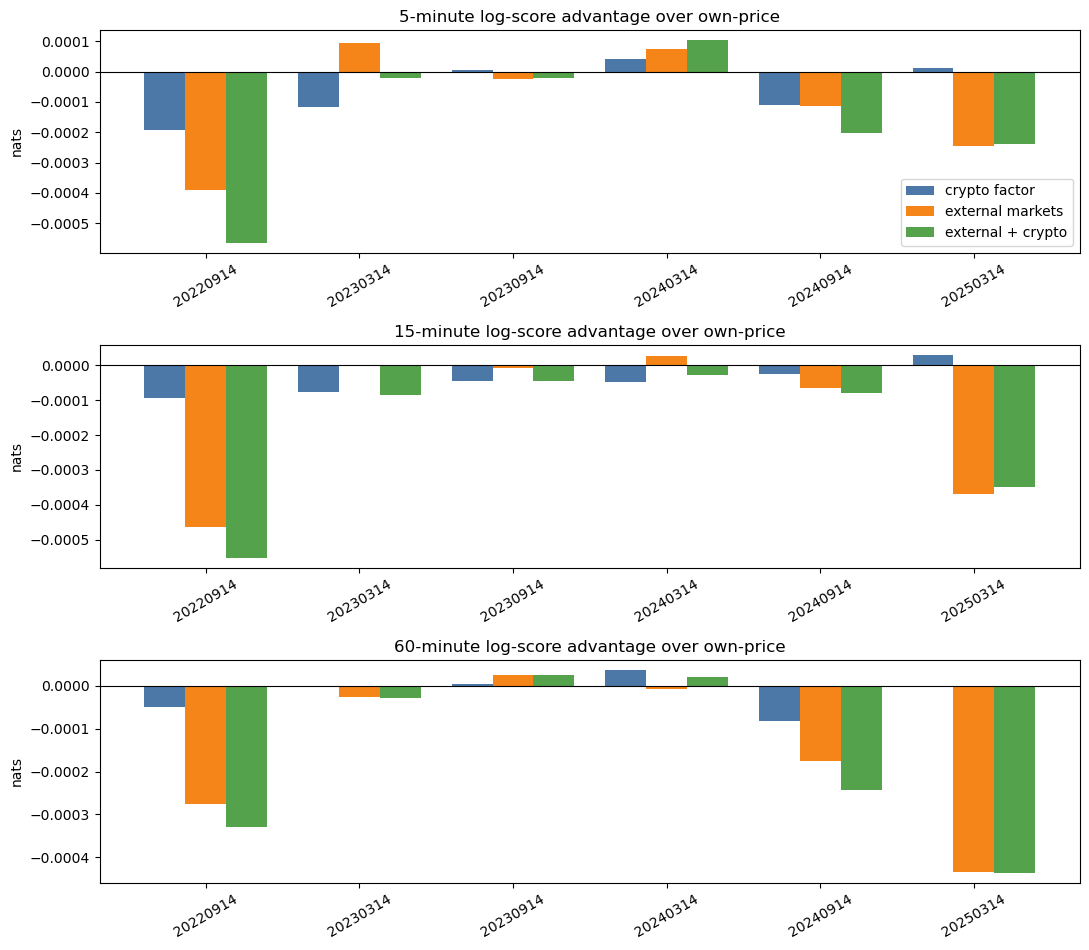

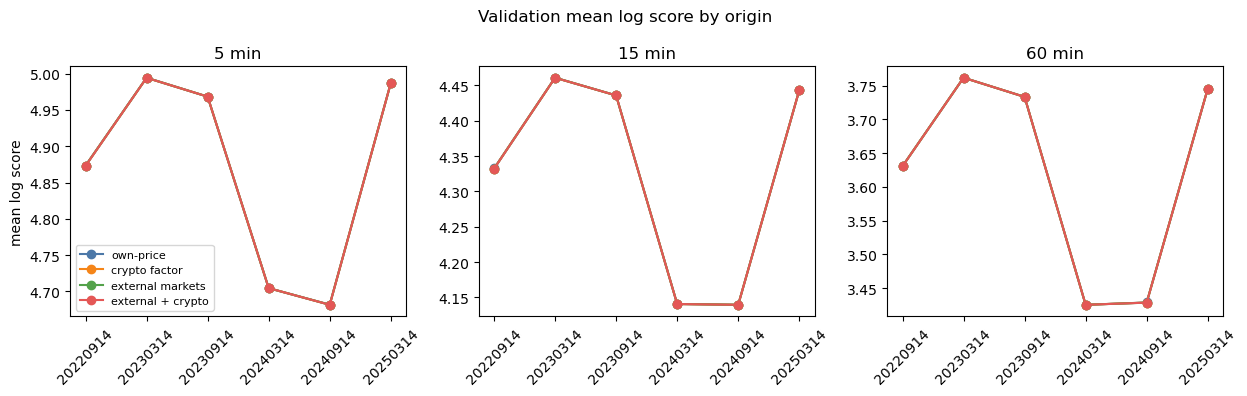

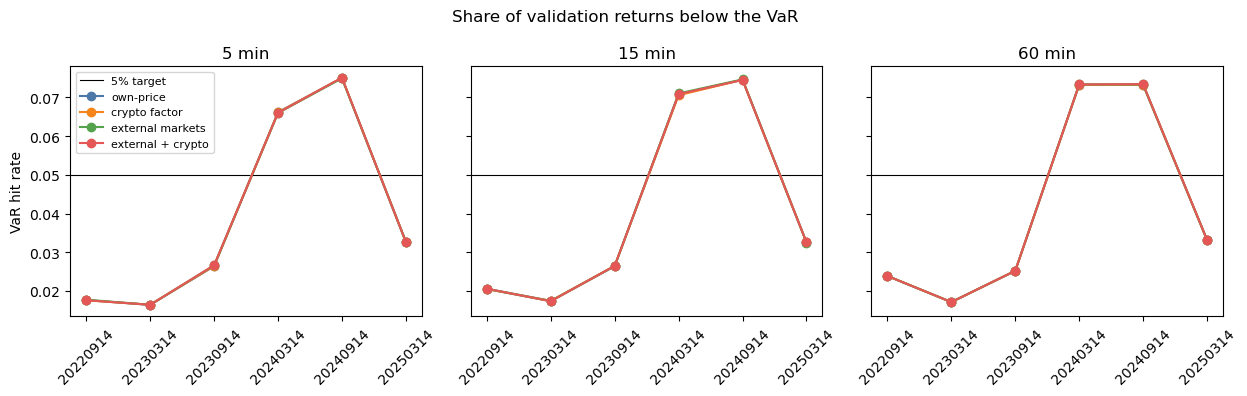

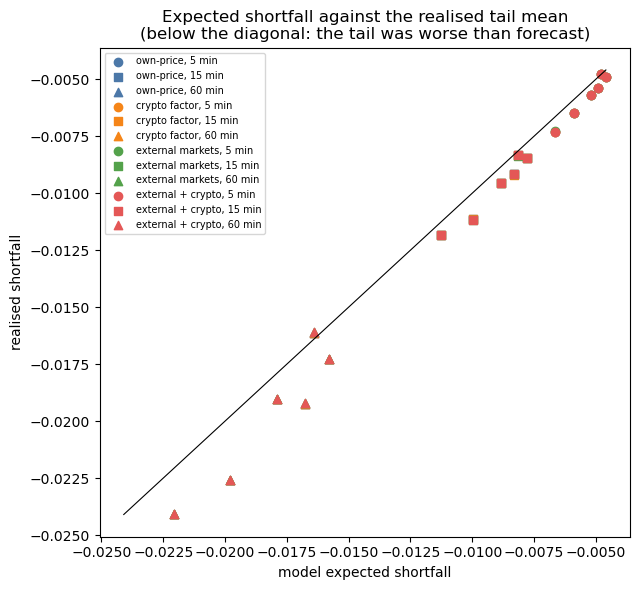

In [5]:
plot_advantage_by_origin(evaluation.scores, benchmark=BENCHMARK, candidates=CANDIDATES, labels=LABELS)
plt.show()
plot_score_levels(evaluation.scores, models=MODELS, labels=LABELS)
plt.show()
plot_var_hit_rates(evaluation.scores, models=MODELS, alpha=ALPHA, labels=LABELS)
plt.show()
plot_shortfall(evaluation.scores, models=MODELS, labels=LABELS)
plt.show()

## Calibration diagnostics

The probability integral transform (PIT) of a well-calibrated density is uniform. Each panel plots PIT quantiles against uniform quantiles. The diagonal is perfect calibration. Faint lines are individual origins and heavy lines are their mean. An S-shaped curve means the tails carry the wrong amount of probability. A candidate improves calibration only if its heavy line sits closer to the diagonal than the benchmark's.

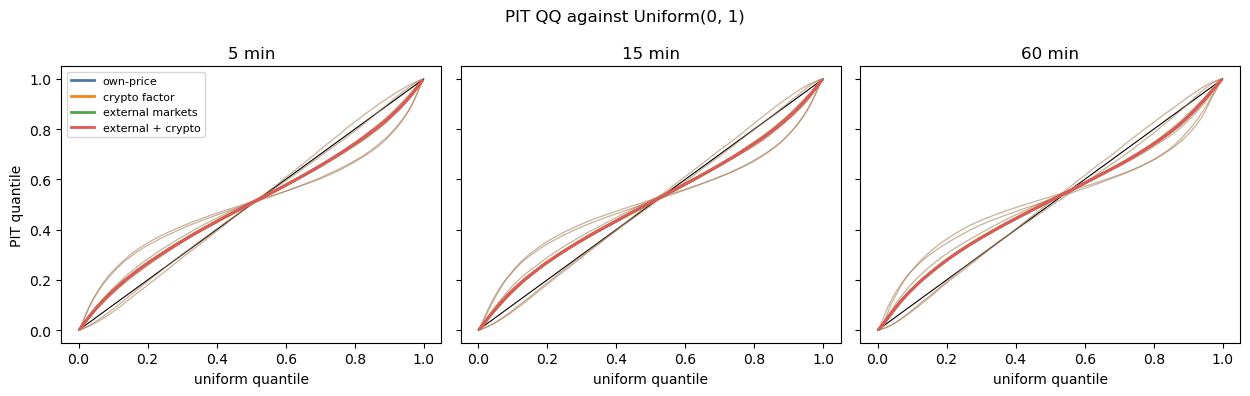

In [6]:
plot_pit_qq(evaluation.pit_qq, models=MODELS, labels=LABELS)
plt.show()

## Fitted densities and state

Every model is a linear forecast of the mean plus an H1-family residual density. Each model is refitted once on all development labels, for display only; the scores above come from the rolling origins.

1. The residual table shows each model's residual family, degrees of freedom, and scale.
2. The coefficient table and bar charts show how far one standard deviation of each lagged feature moves the forecast mean, in basis points. Values near zero mean the feature carries almost no forecast information.
3. The density panels show the benchmark's residual histogram with every model's fitted residual density. Curves that overlap mean the candidates barely change the forecast distribution.

Panel return construction excluded 270062 non-consecutive/initial rows
Excluded 300120 gap and 0 non-positive 5-minute returns
Dropped 133586 own_price training labels with unavailable lagged features
Dropped 133586 crypto_factor training labels with unavailable lagged features
Dropped 133586 external_factor training labels with unavailable lagged features
Dropped 133586 combined training labels with unavailable lagged features
Dropped 133586 own_price display labels with unavailable lagged features
Dropped 133586 crypto_factor display labels with unavailable lagged features
Dropped 133586 external_factor display labels with unavailable lagged features
Dropped 133586 combined display labels with unavailable lagged features
Excluded 307619 gap and 0 non-positive 15-minute returns
Dropped 132589 own_price training labels with unavailable lagged features
Dropped 132589 crypto_factor training labels with unavailable lagged features
Dropped 132589 external_factor training labels with unavai

Residual density of each model, fitted on all development labels


observations    intercept     family      df      scale
horizon_minutes model                                                                   
5               own_price              487131 -9.66177e-06  student_t 4.11876 0.00174698
                crypto_factor          487131 -9.66177e-06  student_t 4.11938 0.00174706
                external_factor        487131 -9.66177e-06  student_t 4.11861  0.0017468
                combined               487131 -9.66177e-06  student_t 4.11927 0.00174689
15              own_price              480628 -2.51725e-05  student_t 4.16419  0.0029703
                crypto_factor          480628 -2.51725e-05  student_t 4.16431 0.00297033
                external_factor        480628 -2.51725e-05  student_t 4.16414 0.00297004
                combined               480628 -2.51725e-05  student_t 4.16428 0.00297007
60              own_price              458372 -7.91306e-05  student_t 4.32423 0.00596372
                crypto_factor          458372 -7.91306e-05  student_t 4.32424 0.00596372
                external_factor        458372 -7.91306e-05  student_t  4.3244 0.00596353
                combined               458372 -7.91306e-05  student_t 4.32442 0.00596354

Forecast mean shift per one-standard-deviation feature move, in basis points


horizon_minutes                                 5           15         60
model           feature                                                  
combined        gold_return               0.136422    0.156433   0.146324
                oil_return              -0.0123083 -0.00287599 -0.0165599
                own_realised_volatility   0.234363     0.75477    2.23882
                own_return               -0.465225   -0.546361  -0.712552
                rate_return             -0.0627296   0.0112844  0.0477282
                single_factor_residual    0.222602    0.181969  0.0951522
                spx_return                 0.20371      0.3482   0.753557
                usd_factor               -0.137296   -0.230654  -0.127342
crypto_factor   own_realised_volatility   0.235102    0.755177    2.23933
                own_return               -0.340665   -0.333854  -0.347286
                single_factor_residual    0.201657    0.143668  0.0282486
external_factor gold_return               0.137121    0.157049   0.146649
                oil_return              -0.0127616 -0.00318309 -0.0168085
                own_realised_volatility   0.231116    0.754016    2.23766
                own_return               -0.332784   -0.436093  -0.655616
                rate_return             -0.0625193   0.0113625  0.0477542
                spx_return                0.190805    0.337025   0.747675
                usd_factor               -0.136306   -0.229784   -0.12693
own_price       own_realised_volatility   0.232128     0.75458    2.23898
                own_return               -0.225227   -0.250227  -0.331069

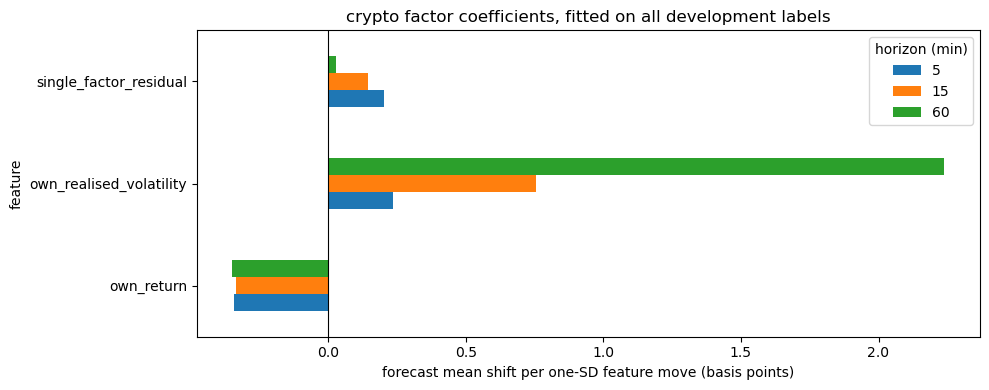

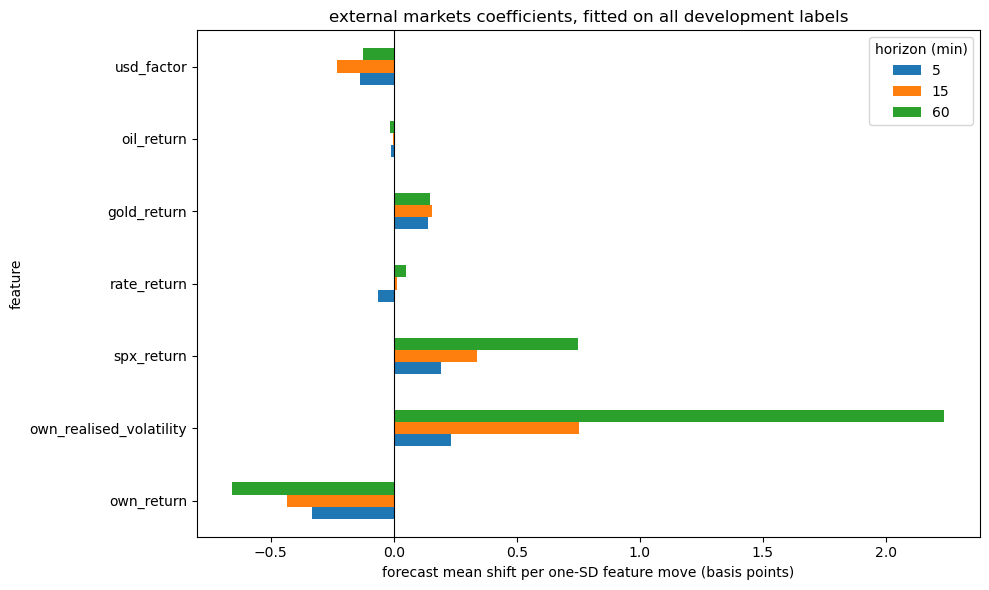

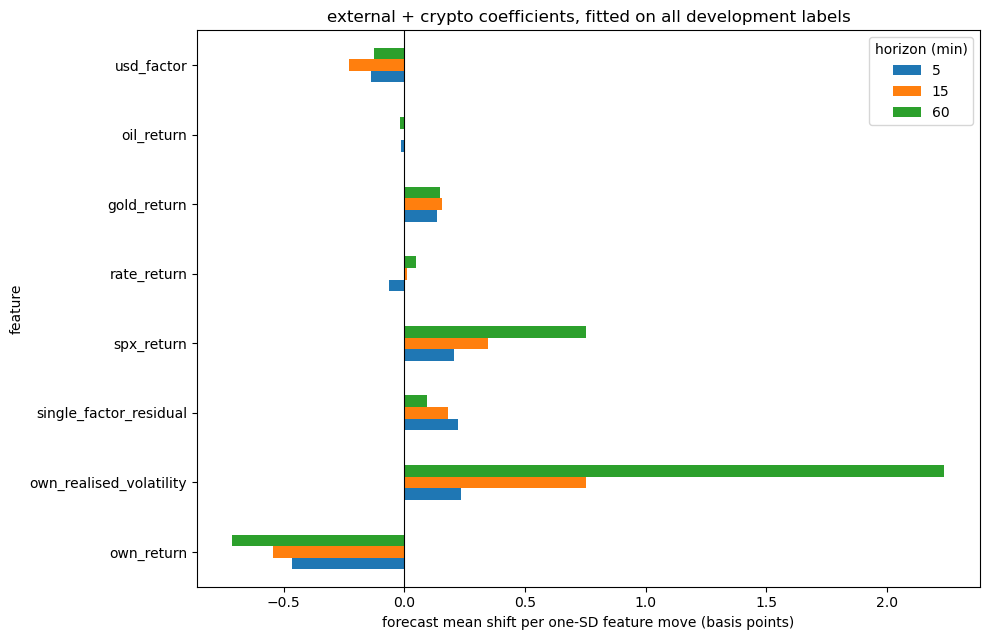

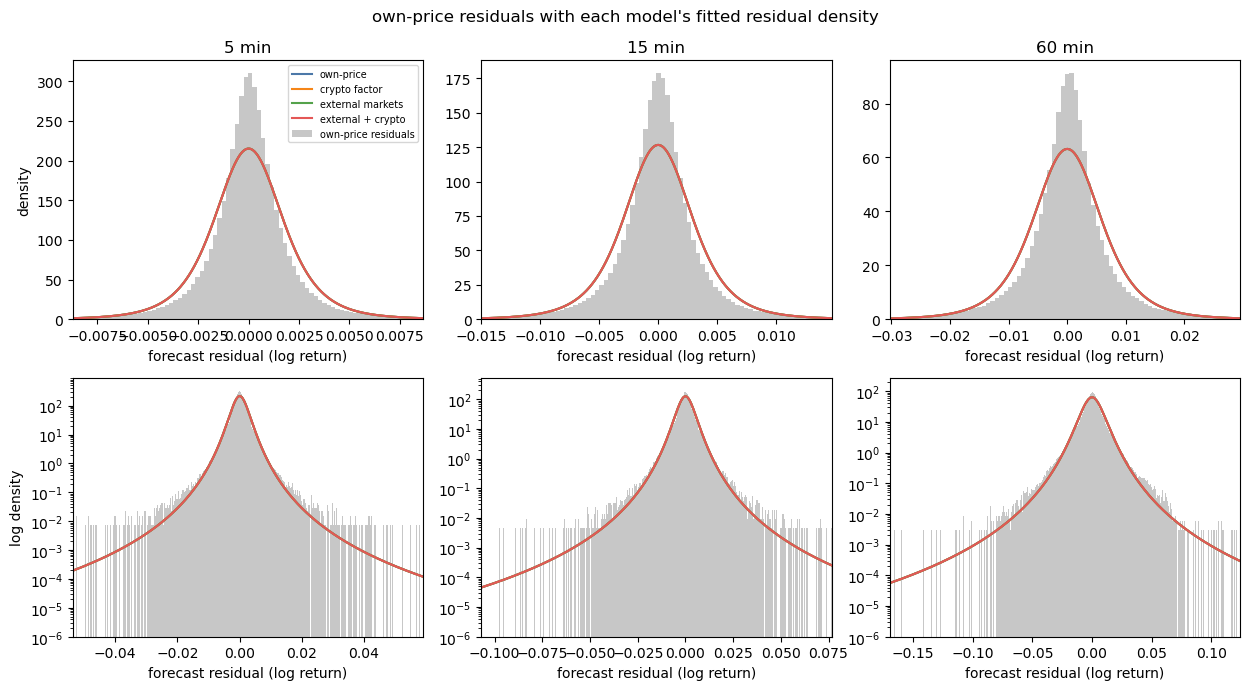

In [7]:
from research.report import conditional_coefficients, plot_coefficients, residual_parameters

fits = h20_development_fits(panel_closes, h1_record, CONFIG)
parameters = residual_parameters(fits)
coefficients = conditional_coefficients(fits)
print("Residual density of each model, fitted on all development labels")
display(parameters.set_index(["horizon_minutes", "model"]))
print("Forecast mean shift per one-standard-deviation feature move, in basis points")
display(
    coefficients.pivot_table(
        index=["model", "feature"], columns="horizon_minutes", values="shift_per_sd_bps", aggfunc="first"
    )
)
for model in CANDIDATES:
    plot_coefficients(coefficients, model=model, labels=LABELS)
    plt.show()

colors = model_colors(MODELS)
samples, curves = {}, {}
for horizon in sorted({fit.horizon_minutes for fit in fits}):
    by_model = {fit.model: fit for fit in fits if fit.horizon_minutes == horizon}
    samples[horizon] = by_model[BENCHMARK].residuals
    curves[horizon] = [
        (LABELS[model], by_model[model].density.residual.log_density, {"color": colors[model]})
        for model in MODELS
    ]
plot_density_panels(
    samples,
    curves,
    title=f"{LABELS[BENCHMARK]} residuals with each model's fitted residual density",
    sample_label=f"{LABELS[BENCHMARK]} residuals",
    xlabel="forecast residual (log return)",
)
plt.show()

external_names = [name for name, _ in CONFIG["external_features"]] + ["usd_factor"]
external = coefficients.loc[(coefficients["model"] == "external_factor") & coefficients["feature"].isin(external_names)]
strongest = external.loc[external["shift_per_sd_bps"].abs().idxmax()]
NOTES = [
    f"External signal size: the largest external coefficient is {strongest.feature} at {int(strongest.horizon_minutes)} "
    f"minutes, moving the BTC forecast mean by {strongest.shift_per_sd_bps:+.3f} basis points per standard deviation. "
    f"That is small against a typical {int(strongest.horizon_minutes)}-minute BTC move.",
    f"Coverage: only {len(panel_closes):,} of {len(panel_closes) + panel_manifest.alignment_exclusions:,} minutes have every "
    f"market open, so the test covers traditional-market sessions. Equity implied volatility was not tested.",
]

## 18. Result

The next cell states the development result in plain English: the answer, why, how large the effect is at each horizon, whether the densities are calibrated, and what to do with the result.

In [8]:
result_lines = plain_english_result(
    question=QUESTION,
    verdict=verdict,
    reading=reading,
    calibration=calibration,
    failures=len(evaluation.failures),
    labels=LABELS,
)
for line in [*result_lines[:-1], *NOTES, result_lines[-1]]:
    print(line)
    print()

Question: Does lagged state from equities, US rates, gold, oil, and the US dollar improve the BTCUSDT return density beyond BTC's own price history?

Answer: no. The null is accepted and the working forecast is own-price.

Why: External-market state does not beat own-price history at every horizon.

Against own-price, crypto factor changed the geometric-mean forecast density by -0.0059% at 5 minutes (ahead at 3 of 6 origins); -0.0043% at 15 minutes (ahead at 1 of 6 origins); -0.0015% at 60 minutes (ahead at 3 of 6 origins).

Against own-price, external markets changed the geometric-mean forecast density by -0.0101% at 5 minutes (ahead at 2 of 6 origins); -0.0147% at 15 minutes (ahead at 1 of 6 origins); -0.0149% at 60 minutes (ahead at 1 of 6 origins).

Against own-price, external + crypto changed the geometric-mean forecast density by -0.0157% at 5 minutes (ahead at 1 of 6 origins); -0.0190% at 15 minutes (ahead at 0 of 6 origins); -0.0164% at 60 minutes (ahead at 2 of 6 origins).

Ta

## 19. Decision

The next cell records the development result on `EXP-H20`. Accepting or rejecting the development null sets status `Exploratory`, names the working forecast in `result`, and leaves the lifecycle decision blank. Incomplete evidence sets `Deferred`. Only `confirm_h20`, run on the sealed year, writes `retain` or `reject`. The cell then lists what still blocks that confirmation.

In [9]:
record = record_development_decision(
    RECORD_PATH,
    verdict,
    experiment_id=EXPERIMENT_ID,
    dataset_id=DATASET_ID,
    dataset_digest=DATASET_DIGEST,
    config=CONFIG,
    root=root,
)
print(f"Recorded on {record.experiment_id}: status={record.status}, result={record.result}, "
      f"lifecycle decision={record.decision or '(blank)'}")
display(pd.Series(asdict(record), name="registry value").to_frame())
blockers = confirmation_blockers(
    root=root,
    record=record,
    h1_record=GATE_H1_RECORD,
    dataset_objects=GATE_OBJECTS,
)
if blockers:
    print("Sealed confirmation is blocked:")
    for blocker in blockers:
        print(f"- {blocker}")
else:
    print("Sealed confirmation has no outstanding blockers. It can be run once, below.")

Research code version is dirty: 53df8883077c46048647a4e3a1a88f5d333bded6+dirty


Recorded on EXP-H20: status=Exploratory, result=own_price, lifecycle decision=(blank)


,registry value
experiment_id,EXP-H20
hypothesis,"Lagged equity, US-rate, gold, oil, and USD-fac..."
null,Lagged external-market state adds no density-f...
parent_hypothesis,EXP-H01
dataset_id,cross-market-1m
dataset_digest,ee0a479c6ead2e2559075b5c0f8b2352683289d7531225...
code_version,53df8883077c46048647a4e3a1a88f5d333bded6+dirty
config_digest,b9e25cf08d6e002f8070876d78b2a49e67752715453cea...
status,Exploratory
result,own_price


Research code version is dirty: 53df8883077c46048647a4e3a1a88f5d333bded6+dirty


Sealed confirmation is blocked:
- the research code is uncommitted (53df8883077c46048647a4e3a1a88f5d333bded6+dirty)
- H1 has not been confirmed on its sealed year
- 16 stored object(s) have no immutable version id, for example ohlcv/binance/BTCUSDT/1m/2026.parquet


## Sealed confirmation

This cell reads the final 12 months once, writes `retain` or `reject` with a run id, and cannot be repeated. It is off by default. Set `RUN_SEALED_CONFIRMATION = True` only after the blockers printed above are cleared and the code is committed.

In [10]:
RUN_SEALED_CONFIRMATION = False

if not RUN_SEALED_CONFIRMATION:
    print("Sealed confirmation was not run. No sealed labels were read.")
else:
    if blockers:
        raise RuntimeError("sealed confirmation is blocked: " + "; ".join(blockers))

    from research.evaluate import confirm_h20

    confirmation = confirm_h20(
        panel_closes,
        record,
        h1_record,
        panel_manifest=panel_manifest,
        root=root,
        record_path=RECORD_PATH,
    )
    print(f"decision={confirmation.record.decision} result={confirmation.record.result} "
          f"status={confirmation.record.status} run_id={confirmation.record.run_id}")
    display(confirmation.scores)

Sealed confirmation was not run. No sealed labels were read.


## 20. Reusable implementation extracted

Cross-venue alignment, lagged external-market state, conditional density scoring, and lifecycle gates live in `research.factors`, `research.manifest`, and `research.evaluate`. `research.report` holds the shared reading, plots, and registration. A rejected H20 result must not enable external-market features in Wave or Tide.

## 21. Next experiment

H4 (`06_wave_probability`) may use external state only if sealed H20 retains it. Adding equity implied volatility, or changing a symbol, sign, or lag, requires a new experiment id.